# Final Project: CFA Predictive Consumption



## Imports

In [ ]:
# File System
import pathlib
import csv
import datetime as dt

# Data Manipulation
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Model
import torch
import torch.optim as optim

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Google Drive Imports
from google.colab import drive

## Data Preparation

### Data Imports

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
data_dir = pathlib.Path('/content/drive/MyDrive/Colab Notebooks/Datasets/CFA/data')
xls_files = list(data_dir.glob("*.xls"))
print(f"Found {len(xls_files)} .xls files in the data directory.")

multipliers_dir = pathlib.Path('/content/drive/MyDrive/Colab Notebooks/Datasets/CFA/multipliers')
multiplier_files = list(multipliers_dir.glob("*.csv"))
print(f"Found {len(multiplier_files)} .csv files in the multipliers directory.")

Found 112 .xls files in the data directory.
Found 4 .csv files in the multipliers directory.


### Multipliers
Some menu items use more than one of their respective proteins. These need to be considered to capture the number of *individual proteins* consumed as opposed to number of *menu items* ordered.

In [ ]:
multiplier_dict : dict[str, int] = {}  # Initialize an empty dictionary to store the mapping of item names to their respective multipliers
# Read the multipliers from the CSV files and populate the multiplier_dict
for file in multiplier_files:
    with open(file, mode='r') as csvfile:
        reader = csv.reader(csvfile)
        for row in reader:
            # Skip the first row if it contains headers (assuming the first row contains headers if it has non-numeric values in the second column)
            if reader.line_num == 1 and (len(row) < 2 or not row[1].strip().isdigit()):
                continue
            if len(row) >= 2:  # Ensure that the row has at least two columns (item name and multiplier)
                item_name = row[0].strip()  # Get the item name and remove any leading/trailing whitespace
                try:
                    multiplier = int(row[1].strip())  # Get the multiplier and convert it to an integer
                    multiplier_dict[item_name] = multiplier  # Add the item name and multiplier to the dictionary
                except ValueError:
                    print(f"Warning: Could not convert multiplier '{row[1]}' for item '{item_name}' to an integer. Skipping this entry.")

print(multiplier_dict)

{'Nugget, 1 Count': 1, 'Nuggets, 12 Count': 12, 'Nuggets, 30 Count': 30, 'Nuggets, 5 Count': 5, 'Nuggets, 8 Count': 8, 'OS - Nuggets , 8 Count': 8, 'Salad - Extra Nuggets': 16, 'Salad - Market w/ Nuggets': 8, 'Salad - Signature Cobb w/ Nuggets': 8, 'Salad - Spicy SW w/ Nuggets': 8, 'Salad - Extra Chick-n-Strips': 6, 'Salad - Market w/ Strips': 3, 'Salad - Signature Cobb w/ Strips': 3, 'Salad - Spicy SW w/ Strips': 3, 'Strip, 1 Count': 1, 'Strips, 10 Count': 10, 'Strips, 2 Count': 2, 'Strips, 3 Count': 3, 'Strips, 4 Count': 4, 'Filet - CFA': 1, 'Jalapeno Ranch Club CFA': 1, 'OS - CFA Sandwich': 1, 'Salad - Extra Chick-fil-A Filet': 2, 'Salad - Market w/ CFA Filet': 1, 'Salad - Signature Cobb w/ CFA Filet': 1, 'Salad - Spicy SW w/ CFA Filet': 1, 'Sandwich - CFA': 1, 'Sandwich - CFA Chicken and Waffles': 1, 'Sandwich - CFA Dlx No Cheese': 1, 'Sandwich - CFA Dlx w/ American': 1, 'Sandwich - CFA Dlx w/ Colby Jack': 1, 'Sandwich - CFA Dlx w/ Pepper Jack': 1, 'Filet - Spicy Chicken': 1, 'Jala

### Data Formatting

The dataset is imported as a series of .xls files containing many artifacts from the internal report generator. These artifacts must be stripped from the file and additional whitespace removed.

In [ ]:
def time_to_interval(interval_str: str) -> int:
    """
    Parses an interval string like "10:30 - 10:45 AM" or "11:15 - 11:30 PM"
    and maps the start time to an integer interval (0-45) from 10:30 AM to 9:45 PM
    and beyond.

    Args:
        interval_str (str): The interval string to be parsed.

    Returns:
        int: The mapped integer interval.
    """
    # "10:30 - 10:45 AM" -> start_part="10:30", end_part="10:45 AM"
    start_part, end_part = [part.strip() for part in interval_str.split("-")]

    period = end_part.split()[-1]  # "AM" or "PM"

    # Determine the start period
    # If the end time is PM, the start time is also PM UNLESS we are spanning across noon (e.g., "11:45 - 12:00 PM")
    start_period = period
    if period == "PM" and (start_part.startswith("11:") or start_part.startswith("10:")) and not end_part.startswith("12:"):
        # E.g. "11:45 AM - 12:00 PM" spans across noon
        if start_part.startswith("11:") and end_part.startswith("12:"):
            start_period = "AM"

    # Parse full start time safely using datetime module
    full_start_str = f"{start_part} {start_period}"
    current_dt = dt.datetime.strptime(full_start_str, "%-I:%M %p")

    # Define index based on 10:30 AM start time
    start_dt = dt.datetime.strptime("10:30 AM", "%I:%M %p")

    # Account for crossing midnight if needed
    if current_dt < start_dt and current_dt.hour < 5: # e.g. early morning of next day
        current_dt += dt.timedelta(days=1)

    delta_minutes = (current_dt - start_dt).total_seconds() / 60
    interval_idx = int(delta_minutes // 15)

    # Boundary check (allowing for times past 45 if necessary, but clamping or returning value)
    if not (0 <= interval_idx <= 45):
        return np.nan

    return interval_idx

In [ ]:
def df_cleaner(df: pd.DataFrame) -> pd.DataFrame:
    '''
    Clean the input DataFrame by converting time intervals to 24-hour format
    and mapping them to integers.

    Args:
        df (pd.DataFrame): The raw input DataFrame directly read from the
                           Excel file.
        protein (str): The name of the protein for which to create a dataframe.

    Returns:
        summed_df: The cleaned and collapsed DataFrame with integer-mapped
                   time invtervals.
    '''

    ### Stripping Report Formatting ###
    # Drop the first 7 rows
    df = df.iloc[7:]
    # Drop report formatting
    df = df.drop(df.columns[1], axis='columns')
    df = df[df.iloc[:, 0] != 'Sales Mix Time Interval Report']
    df = df[df.iloc[:, 0] != 'Store: Indian Trail FSU, 02965']
    df = df[df.iloc[:, 2] != 'Totals:']
    df = df.dropna(axis='columns', how='all')
    # Rename second columns to 'Time Interval'
    df.rename(columns={
        df.columns[0]: 'Menu Item', df.columns[1]: 'Time Interval', df.columns[2]: 'Monday',
        df.columns[3]: 'Tuesday', df.columns[4]: 'Wednesday', df.columns[5]: 'Thursday',
        df.columns[6]: 'Friday', df.columns[7]: 'Saturday'
        }, inplace=True
    )
    # Drop rows with no 'Time Interval' and 'Menu Item' entry
    df = df.dropna(subset=['Time Interval', 'Menu Item'], how='all')
    # Drop any remaining empty rows and columns and clean up NaN values
    df = df.dropna(axis='rows', how='all')
    df = df.dropna(axis='columns', how='all')
    df = df.fillna('')
    df.reset_index(drop=True, inplace=True)

    ### Mapping Time Intervals ###
    # Apply time_to_interval to non-'' values of 'Time Interval'
    df.loc[df['Time Interval'] != '', 'Time Interval'] = df.loc[df['Time Interval'] != '', 'Time Interval'].apply(time_to_interval)
    df = df.dropna(subset=['Time Interval'])
    df.reset_index(drop=True, inplace=True)

    return df

In [ ]:
def df_splitter(df: pd.DataFrame) -> dict[str, pd.DataFrame]:
    '''
    Splits dataframes based on menu item delimiters and returns a dictionary
    of dataframes. Also standardizes size and fills in missing values.

    Args:
        df (pd.DataFrame): The input dataframe to be split.

    Returns:
        split_df (dict[str, pd.DataFrame]): A dictionary containing the split dataframes.
    '''

    ### Split DataFrames by Menu Item ###
    split_df: dict[str, pd.DataFrame] = {}
    current_item = None
    prv_idx = 0

    for index, row in df.iterrows():
        if row['Menu Item'] != '':
            if current_item is not None:
                split_df[current_item] = df.iloc[prv_idx:index].copy()
                prv_idx = index
            current_item = row['Menu Item']
        elif index == df.index[-1]:
            split_df[current_item] = df.iloc[prv_idx+1:index+1].copy()
            split_df[current_item] = split_df[current_item]

    for key in split_df.keys():
        split_df[key].drop(columns=['Menu Item'], inplace=True)
        split_df[key].reset_index(drop=True, inplace=True)

    ### Standardize DataFrame Contents ###
    # Standardize lengths to 46 (0-45)
    all_intervals = list(range(46))

    for key in split_df.keys():
        sub_df = split_df[key]
        # Set 'Time Interval' as index, reindex to fill missing 0-45 steps, reset index, and fill NaNs with 0
        sub_df = (sub_df.set_index('Time Interval')
                        .reindex(all_intervals)
                        .reset_index())

        # Ensure column ordering matches your original layout
        split_df[key] = sub_df[['Time Interval', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']]
        split_df[key].fillna('', inplace=True)
        split_df[key].reset_index(drop=True, inplace=True)

    # Cast to int and fill with 0s
    for key in split_df.keys():
      # Ignore 'Time Interval' column
      for column in split_df[key].columns[1:]:
        split_df[key][column] = pd.to_numeric(split_df[key][column], errors='coerce').fillna(0).astype(int)

    return split_df

In [ ]:
def df_summer(df_set: dict[str, pd.DataFrame]) -> pd.DataFrame:
  '''
  Takes in a set of uniform DataFrames, scales them based on their
  multiplier, and sums them element-wise.

  Args:
    df_set (dict[str, pd.DataFrame]): A dictionary of DataFrames to be summed.

  Returns:
    summed_df: The summed DataFrame with integer-mapped time intervals.
  '''

  summed_df = pd.DataFrame(columns=['Time Interval', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'])
  summed_df.set_index('Time Interval', inplace=True)

  for key in df_set.keys():
    multiplier = multiplier_dict.get(key, 1) # Grab the multiplier.
    temp_df = df_set[key].set_index('Time Interval') # Align via 'Time Interval'
    scaled_df = temp_df * multiplier # Scale the item values.
    summed_df = summed_df.add(scaled_df, fill_value=0) # Add to rolling sum.

  # Reset index once at the end
  summed_df.reset_index(inplace=True)
  return summed_df

In [ ]:
nums : dict[str,int] = {"filets":0, "nuggets":0, "spicy":0, "strips":0}

filets : list[pd.DataFrame] = []
nuggets : list[pd.DataFrame] = []
spicy : list[pd.DataFrame] = []
strips : list[pd.DataFrame] = []

proteins = {
      "filets": filets,
      "nuggets": nuggets,
      "spicy": spicy,
      "strips": strips
    }

for idx, file in enumerate(xls_files):
  category = file.name.lower().split("_")[-1].split(".")[0]
  try:
    df = pd.read_excel(file)
    df = df_cleaner(df)
    split_df = df_splitter(df)
    summed_df = df_summer(split_df)

    for keys in split_df.keys():
      assert split_df[keys].shape == (46, 7)

    nums[category] += 1
    proteins[category].append(summed_df)
  except Exception as e:
    print(f"Error processing {file.name} at index {idx}: {e}")
    break

print(nums)
if not nums["filets"] == nums["nuggets"] == nums["strips"] == nums["spicy"]:
  raise Exception("Unbalanced data imports.")

WARNING *** file size (113901) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (120995) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (115110) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (90403) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (115014) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (136217) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (102338) not 512 + multiple of sector size

### Data Stacking
Each DataFrame currently only contains the information for a single week of sales. To give it a useful format for further manipulations, we will horizontally concatenate each sequential DataFrame to one NumPy array.

In [ ]:
def df_stacker(df_set: list[pd.DataFrame]) -> np.array:
  '''
  Converts a list of DataFrames into a single NumPy array. List items are
  first converted into arrays then horizontally stacked.

  Args:
    df_set (list[pd.DataFrame]): A list of DataFrames to be stacked.

  Returns:
    stacked_df (np.array): The stacked DataFrame as a NumPy array.
  '''

  stacked_arr : np.array = np.empty((46, 0))

  for df in df_set:
    stacked_arr = np.hstack((stacked_arr, df.drop(columns='Time Interval').to_numpy()))

  return stacked_arr

All stacked proteins should take the shape ``` (46, n*6) ``` where ``` n ``` is the number of files or, in this case, weeks worth of data for a given protein.


In [ ]:
stacked_proteins : dict[str, np.array] = {}

for key in proteins.keys():
  stacked_proteins[key] = df_stacker(proteins[key])
  print(f"{key}: {stacked_proteins[key].shape}")
  assert stacked_proteins[key].shape == (46, nums[key]*6), "Malformed data array."

filets: (46, 168)
nuggets: (46, 168)
spicy: (46, 168)
strips: (46, 168)


### Data Visualization

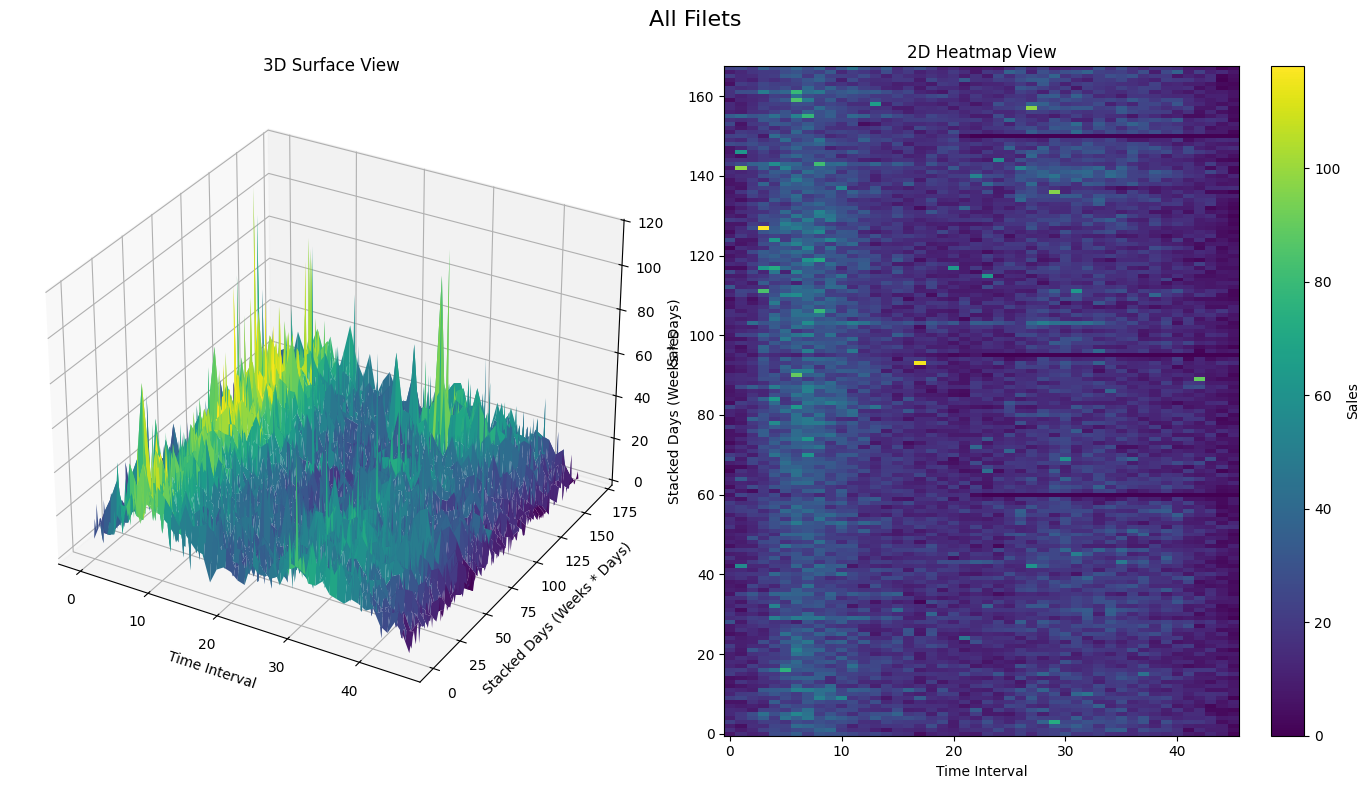

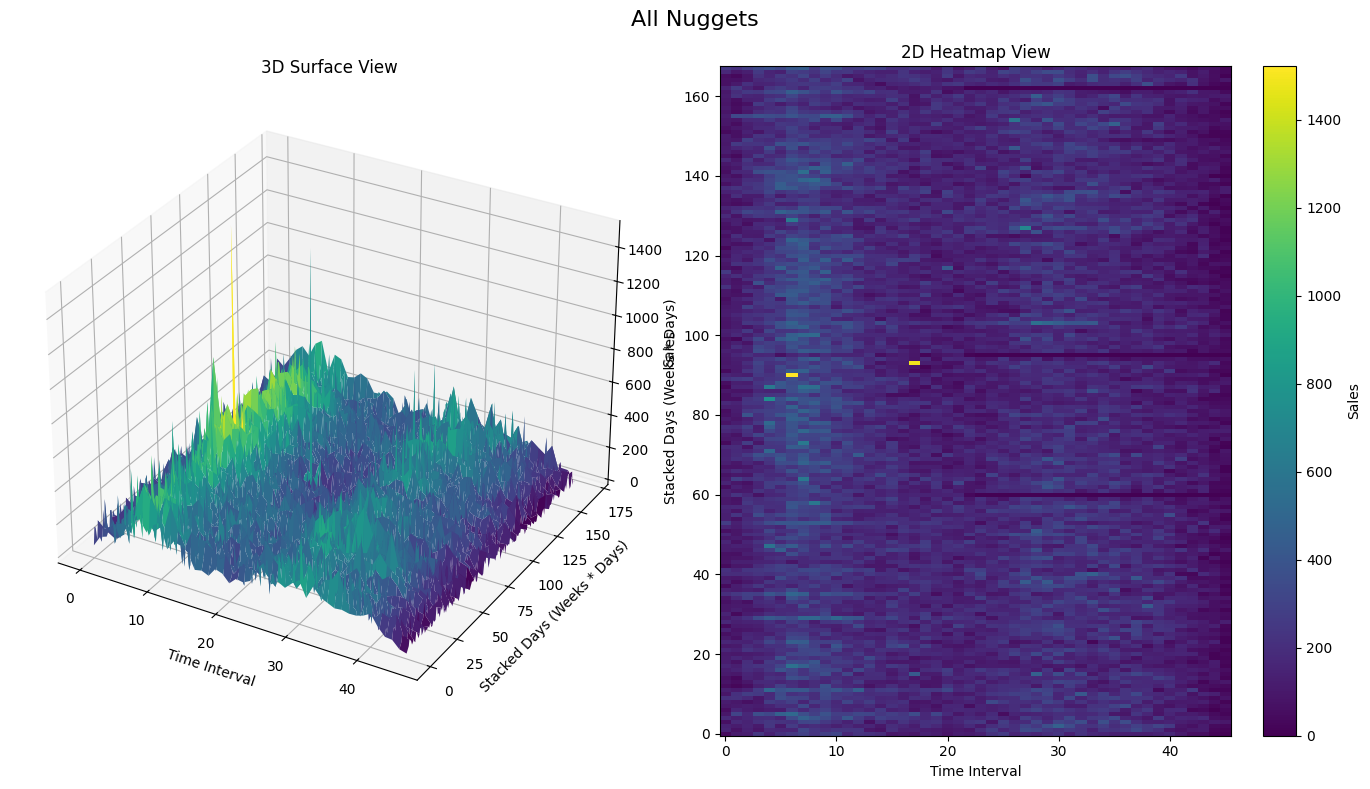

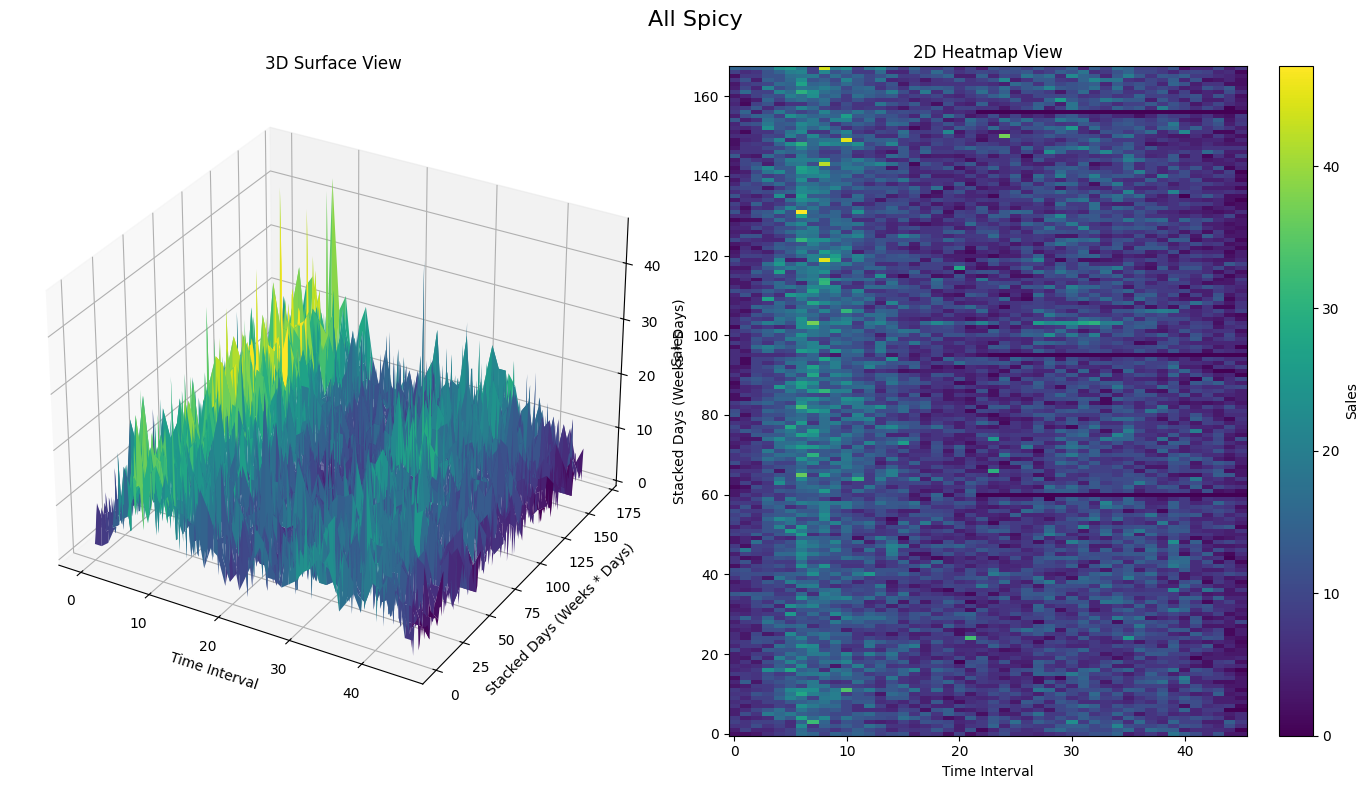

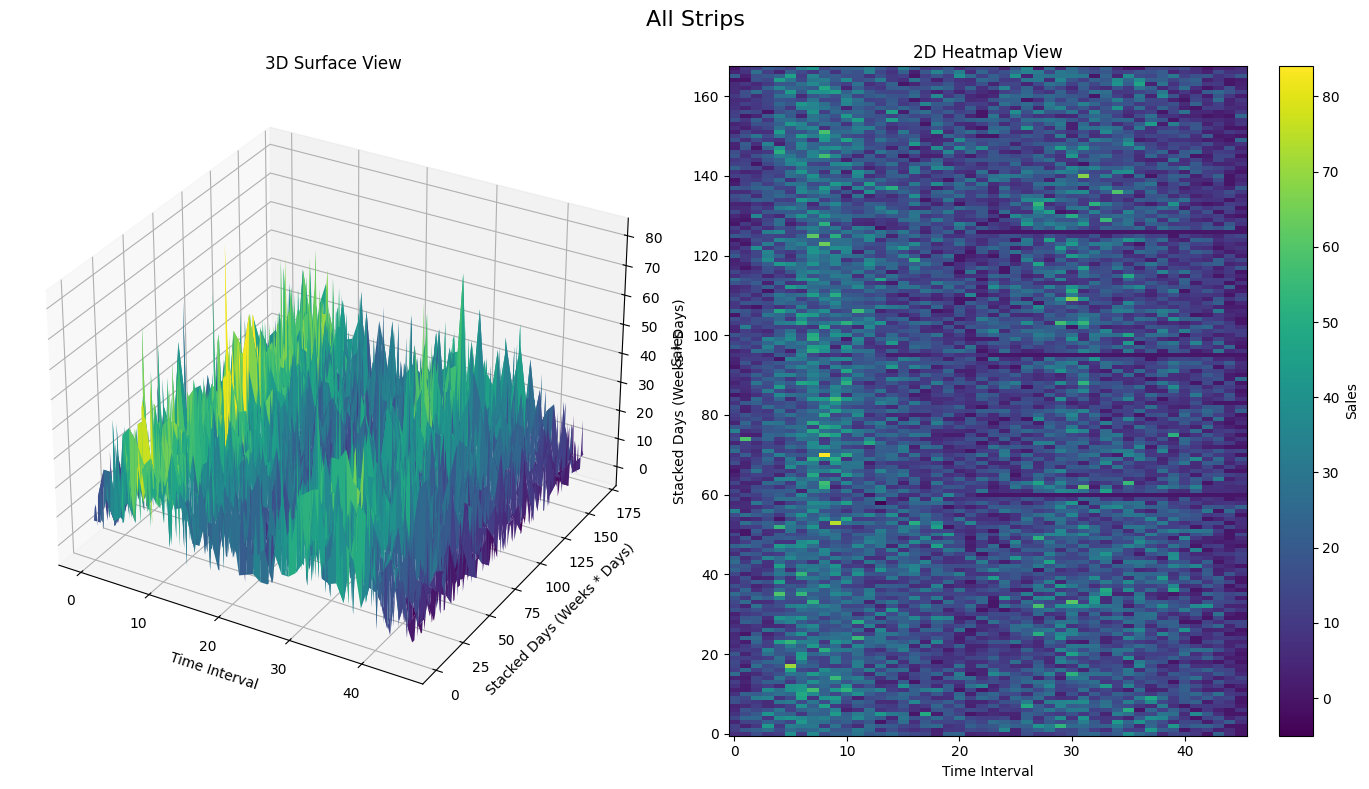

In [ ]:
for category, data_arr in stacked_proteins.items():
    fig = plt.figure(figsize=(14, 8))

    # x coordinate corresponds to the 46 intervals (0 to 45)
    x = np.arange(46)
    # y coordinate corresponds to the 168 stacked days (28 weeks * 6 days/week)
    y = np.arange(data_arr.shape[1])

    X, Y = np.meshgrid(x, y)
    # Convert the array to float dtype so matplotlib can process it
    Z = data_arr.T.astype(float)

    # 3D Surface
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    surf = ax1.plot_surface(X, Y, Z, cmap='viridis')
    ax1.set_xlabel('Time Interval')
    ax1.set_ylabel('Stacked Days (Weeks * Days)')
    ax1.set_zlabel('Sales')
    ax1.set_title('3D Surface View')

    # 2D Heat Map
    ax2 = fig.add_subplot(1, 2, 2)
    mesh = ax2.pcolormesh(X, Y, Z, cmap='viridis', shading='auto')
    ax2.set_xlabel('Time Interval')
    ax2.set_ylabel('Stacked Days (Weeks * Days)')
    ax2.set_title('2D Heatmap View')

    # Add a colorbar next to the 2D plot
    cbar = fig.colorbar(mesh, ax=ax2)
    cbar.set_label('Sales')

    # Main title using the category key name
    fig.suptitle(f'All {category.capitalize()}', fontsize=16)

    plt.tight_layout()
    plt.show()